<a href="https://colab.research.google.com/github/gurpreet23py/QP--001-Quantum-Processor-/blob/main/QP_001_Quantum_Processor_Simulator_ipynb_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QP-001: Advanced Quantum Processor Simulator

This notebook demonstrates a more advanced quantum processor simulation workflow using Qiskit and PennyLane. It covers:
- Bell-state preparation
- GHZ-state generation
- Noise modeling
- Quantum error correction with repetition code
- Basic processor abstraction for experiment orchestration

The goal is to move from simple examples to a cleaner and more reusable quantum processor simulation project.


In [1]:
# Install and verify required packages
!python -m pip install --quiet qiskit qiskit-aer pennylane numpy matplotlib seaborn

import sys
import json
import math
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import qiskit
import qiskit_aer
import pennylane as qml

print("Python:", sys.version.split()[0])
print("Qiskit:", qiskit.__version__)
print("Qiskit Aer:", qiskit_aer.__version__)
print("PennyLane:", qml.__version__)


Python: 3.13.18
Qiskit: 2.6.2
Qiskit Aer: 0.18.2
PennyLane: 0.45.1


## 1) Bell-state simulation with Qiskit

This is a foundational quantum state where two qubits are entangled. The two valid outcomes are "00" and "11" with equal probability.


Circuit Diagram:
     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 

Bell measurement counts: {'00': 491, '11': 533}


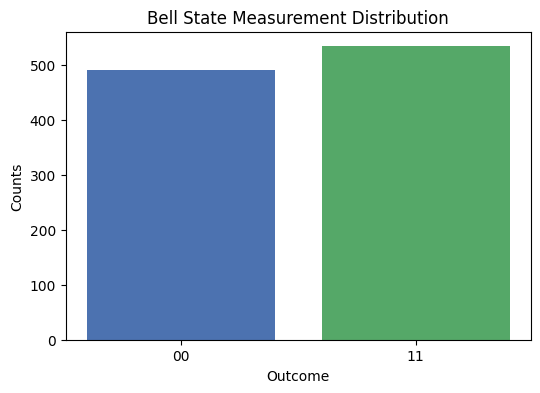

In [3]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt

bell = QuantumCircuit(2, 2)
bell.h(0)
bell.cx(0, 1)
bell.measure([0, 1], [0, 1])

# Changed output from 'mpl' to 'text' to avoid the pylatexenc dependency
print("Circuit Diagram:")
print(bell.draw(output="text"))

sim = AerSimulator()
result = sim.run(bell, shots=1024).result()
counts = result.get_counts()
print("\nBell measurement counts:", counts)

# Visualize distribution
plt.figure(figsize=(6, 4))
plt.bar(counts.keys(), counts.values(), color=["#4C72B0", "#55A868"])
plt.title("Bell State Measurement Distribution")
plt.xlabel("Outcome")
plt.ylabel("Counts")
plt.show()

## 2) GHZ processor experiment

The Greenberger-Horne-Zeilinger (GHZ) state creates a highly entangled system. For an 8-qubit GHZ state, the system should be dominated by "00000000" and "11111111" outcomes with equal probability.


     ┌───┐          ┌─┐                                              
q_0: ┤ H ├──■───────┤M├──────────────────────────────────────────────
     └───┘┌─┴─┐     └╥┘     ┌─┐                                      
q_1: ─────┤ X ├──■───╫──────┤M├──────────────────────────────────────
          └───┘┌─┴─┐ ║      └╥┘     ┌─┐                              
q_2: ──────────┤ X ├─╫───■───╫──────┤M├──────────────────────────────
               └───┘ ║ ┌─┴─┐ ║      └╥┘     ┌─┐                      
q_3: ────────────────╫─┤ X ├─╫───■───╫──────┤M├──────────────────────
                     ║ └───┘ ║ ┌─┴─┐ ║      └╥┘     ┌─┐              
q_4: ────────────────╫───────╫─┤ X ├─╫───■───╫──────┤M├──────────────
                     ║       ║ └───┘ ║ ┌─┴─┐ ║      └╥┘     ┌─┐      
q_5: ────────────────╫───────╫───────╫─┤ X ├─╫───■───╫──────┤M├──────
                     ║       ║       ║ └───┘ ║ ┌─┴─┐ ║      └╥┘┌─┐   
q_6: ────────────────╫───────╫───────╫───────╫─┤ X ├─╫───■───╫─┤M├───
                    

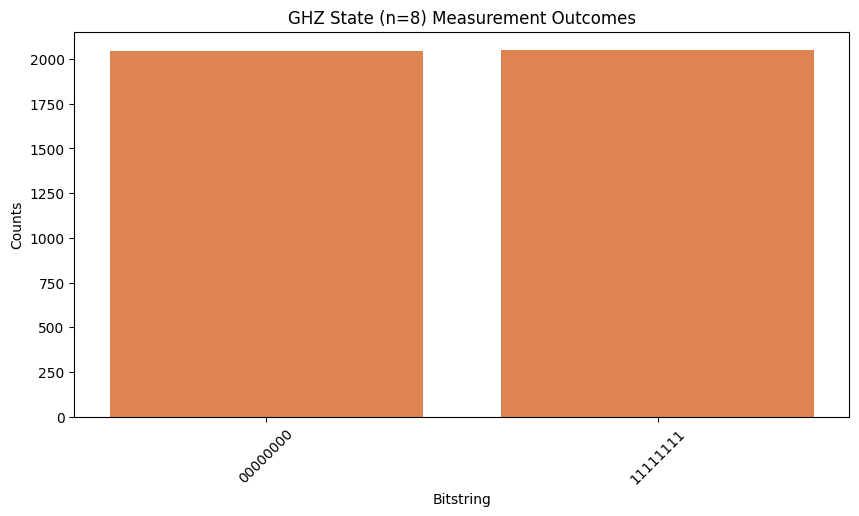

In [4]:
def ghz_state(n_qubits=8):
    qc = QuantumCircuit(n_qubits, n_qubits)
    qc.h(0)
    for i in range(n_qubits - 1):
        qc.cx(i, i + 1)
    qc.measure(range(n_qubits), range(n_qubits))
    return qc

n = 8
qc_ghz = ghz_state(n)
print(qc_ghz)

sim = AerSimulator()
result = sim.run(qc_ghz, shots=4096).result()
counts = result.get_counts()

filtered = {k: v for k, v in counts.items() if v > 10}
print("Important GHZ outcomes:", filtered)

# Show all significant outcomes
labels = list(filtered.keys())
values = list(filtered.values())
plt.figure(figsize=(10, 5))
plt.bar(labels, values, color="#DD8452")
plt.title(f"GHZ State (n={n}) Measurement Outcomes")
plt.xlabel("Bitstring")
plt.ylabel("Counts")
plt.xticks(rotation=45)
plt.show()


## 3) PennyLane: parameterized circuit and gradient

PennyLane is useful for differentiable quantum circuits and hybrid optimization workflows.


In [8]:
dev = qml.device("default.qubit", wires=1)

@qml.qnode(dev, shots=None)
def circuit(phi1, phi2):
    qml.RX(phi1, wires=0)
    qml.RY(phi2, wires=0)
    return qml.expval(qml.PauliZ(0))

def cost(x, y):
    # Use PennyLane's wrapped numpy to support automatic differentiation on operators
    return qml.numpy.sin(qml.numpy.abs(circuit(x, y))) - 1

# Use PennyLane's wrapped numpy to support requires_grad
phi1 = qml.numpy.array(0.5, requires_grad=True)
phi2 = qml.numpy.array(0.5, requires_grad=True)
dcost = qml.grad(cost, argnums=[0, 1])
gradient = dcost(phi1, phi2)
print("Gradient:", gradient)

Gradient: (tensor(-0.30200622, requires_grad=True), tensor(-0.30200622, requires_grad=True))


## 4) Noise simulation

Noisy quantum devices are a practical reality. Here we simulate a depolarizing error model on a GHZ processor.


In [9]:
n = 8
noise_level = 0.01
shots = 2000

dev_noisy = qml.device("default.mixed", wires=n)

@qml.qnode(dev_noisy, shots=shots)
def noisy_ghz_processor():
    qml.Hadamard(wires=0)
    for i in range(n - 1):
        qml.CNOT(wires=[i, i + 1])
        qml.DepolarizingChannel(noise_level, wires=i)
        qml.DepolarizingChannel(noise_level, wires=i + 1)
    return qml.sample(wires=range(n))

samples = noisy_ghz_processor()
states, counts = np.unique(samples, axis=0, return_counts=True)

measurement_counts = {
    "".join(map(str, state)): int(count) for state, count in zip(states, counts)
}

zero_state = "0" * n
one_state = "1" * n
zero_count = measurement_counts.get(zero_state, 0)
one_count = measurement_counts.get(one_state, 0)
ghz_count = zero_count + one_count
ghz_percentage = (ghz_count / shots) * 100

print("Noise level:", noise_level)
print("Shots:", shots)
print("Zero-state count:", zero_count)
print("One-state count:", one_count)
print("GHZ-state percentage:", round(ghz_percentage, 2), "%")

# Print top error outcomes
for bitstring, count in sorted(measurement_counts.items(), key=lambda item: item[1], reverse=True)[:10]:
    print(f"{bitstring}: {count}")


Noise level: 0.01
Shots: 2000
Zero-state count: 956
One-state count: 889
GHZ-state percentage: 92.25 %
00000000: 956
11111111: 889
01111111: 12
00000010: 10
00000100: 9
11111000: 9
11111100: 9
00001000: 8
11110000: 8
11110111: 7


## 5) Quantum error correction: repetition code

We will encode a logical state into three physical qubits and use a majority vote decoder to detect bit-flip errors.


In [10]:
def repetition_code_experiment(error_rate=0.05, shots=5000):
    dev = qml.device("default.mixed", wires=3)

    @qml.qnode(dev, shots=shots)
    def noisy_repetition_code():
        qml.PauliX(wires=0)
        qml.CNOT(wires=[0, 1])
        qml.CNOT(wires=[0, 2])
        for i in range(3):
            qml.BitFlip(error_rate, wires=i)
        return qml.sample(wires=[0, 1, 2])

    results = noisy_repetition_code()

    raw_errors = np.sum(results[:, 0] != 1)
    corrected_bits = (np.sum(results, axis=1) >= 2).astype(int)
    corrected_errors = np.sum(corrected_bits != 1)

    return {
        "raw_errors": int(raw_errors),
        "corrected_errors": int(corrected_errors),
        "raw_error_percentage": (raw_errors / shots) * 100,
        "corrected_error_percentage": (corrected_errors / shots) * 100,
        "results": results,
    }

experiment = repetition_code_experiment()
print("Raw errors:", experiment["raw_errors"])
print("Corrected errors:", experiment["corrected_errors"])
print("Raw error percentage:", round(experiment["raw_error_percentage"], 2), "%")
print("Corrected error percentage:", round(experiment["corrected_error_percentage"], 2), "%")


Raw errors: 215
Corrected errors: 29
Raw error percentage: 4.3 %
Corrected error percentage: 0.58 %


## 6) Building a reusable quantum processor abstraction

This structure makes the notebook more project-like. It separates the simulation setup from the experiments.


In [11]:
class QuantumProcessorSimulator:
    def __init__(self, qubits=4, noise_level=0.0):
        self.qubits = qubits
        self.noise_level = noise_level
        self.device = qml.device("default.mixed" if noise_level > 0 else "default.qubit", wires=qubits)

    def bell_state(self, shots=1024):
        @qml.qnode(self.device, shots=shots)
        def circuit():
            qml.Hadamard(0)
            qml.CNOT([0, 1])
            return qml.sample(wires=[0, 1])
        return circuit()

    def ghz_state(self, shots=1024):
        @qml.qnode(self.device, shots=shots)
        def circuit():
            qml.Hadamard(0)
            for i in range(self.qubits - 1):
                qml.CNOT([i, i + 1])
            return qml.sample(wires=range(self.qubits))
        return circuit()

    def summary(self):
        print(f"Quantum processor initialized with {self.qubits} qubits")
        print(f"Noise model active: {self.noise_level > 0}")


sim = QuantumProcessorSimulator(qubits=4, noise_level=0.0)
sim.summary()
print("Bell samples:", sim.bell_state(shots=100)[:10])
print("GHZ samples:", sim.ghz_state(shots=20)[:10])


Quantum processor initialized with 4 qubits
Noise model active: False
Bell samples: [[1 1]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [1 1]
 [0 0]]
GHZ samples: [[0 0 0 0]
 [1 1 1 1]
 [1 1 1 1]
 [0 0 0 0]
 [1 1 1 1]
 [1 1 1 1]
 [1 1 1 1]
 [0 0 0 0]
 [1 1 1 1]
 [1 1 1 1]]


## 7) Final notes

This notebook is a better foundation for a real project because it:
- avoids excessive repetition
- separates experimentation from architecture
- uses cleaner code blocks
- includes noise and error correction concepts
- introduces a more reusable processor simulator abstraction

For a production-grade project, the next step would be to add:
- a proper README
- dependency pinning via requirements.txt
- plotting/reporting utilities
- unit tests
- modular source files instead of a single notebook
